# Vorstudie: MSE vs. SPO+ mit linearem Modell (PyEPO, Knapsack)

**Aufbau** (Code in [prestudy.py](../../src/prestudy.py), `problem="knapsack"`)
- 2-dimensionaler 0-1-Knapsack mit 32 Items und Kapazität 20 je Dimension; Gewichte fest, aus {3,00; …; 7,99} gezogen (Setting von Tang & Khalil 2024). Pro Instanz passen etwa 4 Items.
- Unsicher sind nur die Item-*Werte* (Zielfunktion), die Gewichte stehen in den Nebenbedingungen und sind bekannt. Maximiert wird; Regret = entgangener Wert gegenüber der optimalen Auswahl, normiert mit $\sum |z^*|$.
- PyEPO-Standardgenerator `pyepo.data.knapsack.genData`: $c = \big\lceil 5\,[(Bx/\sqrt p + 3)^{deg} + 1] / 3.5^{deg} \cdot \varepsilon \big\rceil$ mit zufälligem $B$, p = 5 Features
- Raster: deg ∈ {1, 2, 4, 6} × noise ∈ {0, 0.5} × n ∈ {100, 1000}; m = 5 Refits auf disjunkten Trainingsblöcken aus *einem* `genData`-Aufruf je (deg, noise), $n_{test}$ = 1000
- Modell, Training und PFI wie beim Shortest Path: `nn.Linear(5, 32)` ohne Regularisierung, Adam, Lernrate 0,01 linear fallend, 3000 Schritte, Batch 32; K = 10 Permutationen, gepaart über die Losses
- Gurobi löst jedes Problem exakt als binäres IP, auch im SPO+-Training (keine LP-Relaxation)
- Skalenbereinigung: nur $s\,\hat c$ mit $s > 0$. Beim Knapsack ist anders als im Gitter keine Verschiebung entscheidungsneutral.
- Referenz: Orakel $E[c \mid x]$ *einschließlich* Aufrunden (geschlossene Form in `expected_ceil`)

In [1]:
import pandas as pd

import prestudy as v

CSV = v.result_path("knapsack", "pyepo")
if not CSV.exists():
    v.run("knapsack", "pyepo").to_csv(CSV, index=False)  # ca. 15–20 min parallel (Knapsack-Solves sind teurer)
df = pd.read_csv(CSV)
pd.set_option("display.precision", 4)

Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Set parameter Username
Set parameter LicenseID to value 2875352
Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Academic license - for non-commercial use only - expires 2027-10-16
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Academic lic

Welche Features wirken auf wie viele der 32 Items? ($B$ ist der zweite Zug aus `RandomState(0)` in `genData`, nach den Gewichten.)

In [2]:
_, B, weights, caps = v.structure("knapsack", "pyepo", 32, 0)
pd.Series(B.sum(0), index=[f"x{j + 1}" for j in range(B.shape[1])], name="Items")

x1    20
x2    14
x3    17
x4    15
x5    17
Name: Items, dtype: int64

## 1 Modellgüte auf der Testmenge

Mittelwerte über die 5 Refits. `mse_adj` ist der MSE nach der entscheidungsneutralen Skalierung $s\,\hat c$.

In [3]:
(v.performance(df).query("loss != 'oracle'")
 .groupby(["noise", "n", "deg", "loss"])[["mse", "mse_adj", "regret"]].mean()
 .unstack("loss"))

mse           mse_adj           regret        
loss                  mse     spo+      mse     spo+     mse    spo+
noise n      deg                                                    
0.0   100.0  1     0.0870  29.5496   0.0867  27.5115  0.0009  0.0025
             2     0.1941  13.9309   0.1941  12.6980  0.0049  0.0079
             4     2.6083  12.6442   2.6075  12.6604  0.0349  0.0122
             6    16.9838  32.9292  17.1676  31.7373  0.0971  0.0209
      1000.0 1     0.0824  25.9066   0.0821  22.2063  0.0008  0.0011
             2     0.1777   9.7493   0.1777   6.6207  0.0042  0.0025
             4     2.3465  11.6663   2.3468  11.5775  0.0266  0.0035
             6    15.5312  33.5194  15.5694  30.5835  0.0801  0.0063
0.5   100.0  1     3.0513  22.8331   3.0535  19.6490  0.1176  0.1313
             2     2.0861  14.5481   2.0864  14.0140  0.1231  0.1366
             4     4.8660  17.1419   4.8649  17.0340  0.1282  0.1211
             6    21.7797  38.6275  22.0397  38.7425  0.1667  0.1112
      1000.0 1     2.8911  14.6186   2.8913   6.4828  0.1122  0.1143
             2     1.9567   9.9015   1.9568   6.4821  0.1170  0.1155
             4     4.4198  13.7376   4.4201  13.7001  0.1158  0.0947
             6    19.9784  35.7004  20.0238  35.4567  0.1483  0.0816

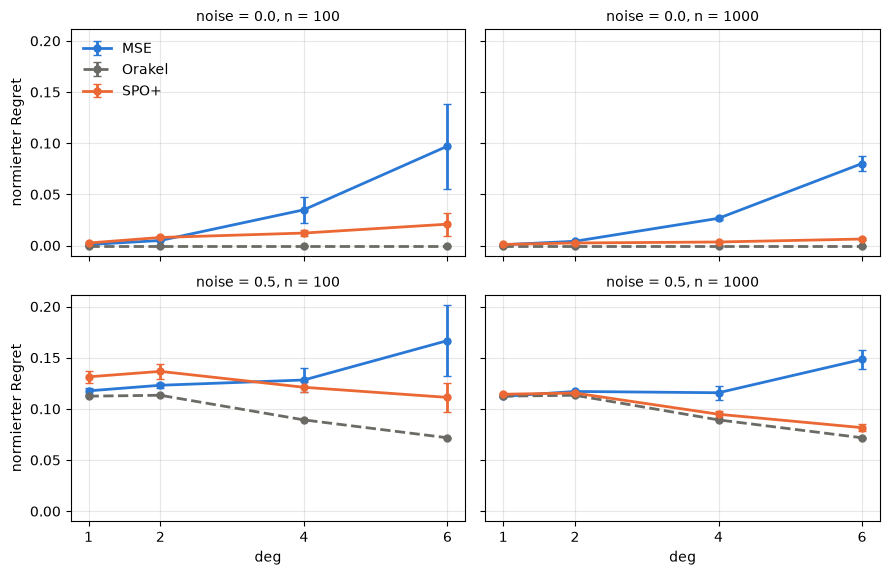

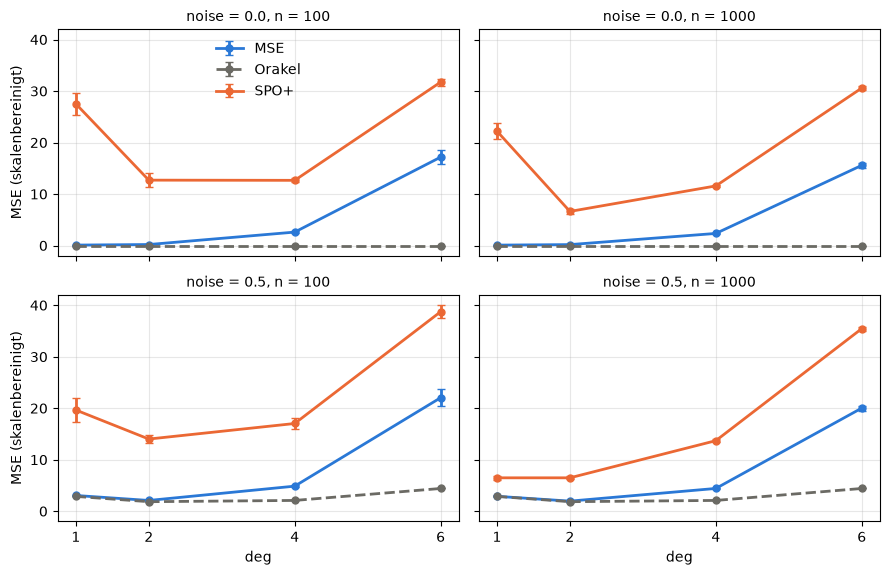

In [4]:
v.plot_over_deg(df, "regret", "normierter Regret")
v.plot_over_deg(df, "mse_adj", "MSE (skalenbereinigt)")

## 2 PFI je Feature

Balken: Mittelwert über die Refits mit 95-%-KI; graue Striche: Orakel. Standard ist n = 1000, noise = 0.5; die Parameter lassen sich ändern.

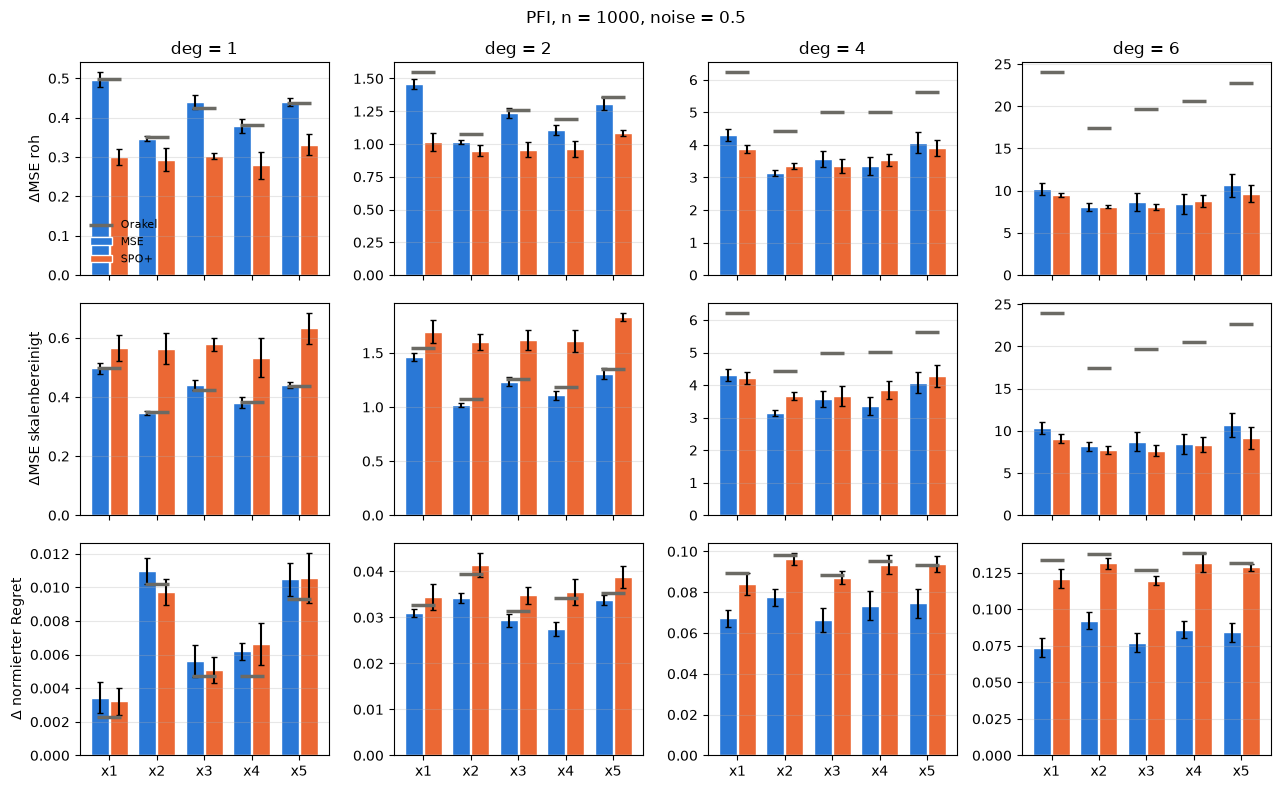

In [5]:
v.plot_pfi(df)

## 3 H1: Rangfolge nach ΔMSE vs. ΔRegret

Kendall's τ zwischen den Rangfolgen der 5 Features nach ΔMSE (skalenbereinigt) und nach ΔRegret, je Modell und Refit berechnet, dann über die Refits gemittelt. Bei 5 Features nimmt τ nur 11 Werte an.

In [6]:
v.kendall_tau(df)

loss               mse  oracle  spo+
noise n      deg                    
0.0   100.0  1   -0.24     NaN  0.44
             2   -0.04     NaN  0.32
             4   -0.24     NaN  0.00
             6    0.00     NaN  0.20
      1000.0 1   -0.20     NaN  0.20
             2    0.04     NaN  0.36
             4   -0.12     NaN -0.20
             6   -0.40     NaN  0.32
      NaN    1     NaN     0.0   NaN
             2     NaN     0.4   NaN
             4     NaN    -0.2   NaN
             6     NaN     0.2   NaN
0.5   100.0  1   -0.28     NaN  0.08
             2    0.08     NaN  0.08
             4   -0.24     NaN -0.08
             6   -0.12     NaN -0.08
      1000.0 1   -0.60     NaN  0.24
             2    0.00     NaN  0.04
             4   -0.36     NaN -0.20
             6   -0.40     NaN -0.12
      NaN    1     NaN    -0.6   NaN
             2     NaN    -0.4   NaN
             4     NaN    -0.4   NaN
             6     NaN     0.0   NaN

## 4 Loss-Effekt je Feature: gepaarte Differenz SPO+ − MSE

Je Refit $D_j = \mathrm{PFI}_j(\text{SPO+}) - \mathrm{PFI}_j(\text{MSE})$, Mittelwert und 95-%-t-Intervall über die 5 Refits. `*` = Intervall schließt 0 aus (ohne Holm-Korrektur, nur als Pilot).

In [7]:
v.paired_diff(df).unstack("deg").loc[(0.5, 1000)]

d_mse_adj                                          \
deg                       1                   2                   4   
feature                                                               
x1       +0.0682 ± 0.0380 *  +0.2366 ± 0.1046 *    -0.0814 ± 0.2432   
x2       +0.2170 ± 0.0479 *  +0.5839 ± 0.0669 *  +0.5163 ± 0.0875 *   
x3       +0.1371 ± 0.0209 *  +0.3806 ± 0.0802 *    +0.1071 ± 0.1771   
x4       +0.1523 ± 0.0770 *  +0.5041 ± 0.0945 *  +0.5021 ± 0.2698 *   
x5       +0.1914 ± 0.0525 *  +0.5264 ± 0.0543 *  +0.2013 ± 0.1851 *   

                                     d_regret                      \
deg                       6                 1                   2   
feature                                                             
x1       -1.2340 ± 0.6079 *  -0.0002 ± 0.0004  +0.0035 ± 0.0022 *   
x2       -0.4641 ± 0.2062 *  -0.0012 ± 0.0014  +0.0072 ± 0.0016 *   
x3       -1.0649 ± 0.5140 *  -0.0006 ± 0.0010  +0.0054 ± 0.0025 *   
x4         -0.1000 ± 0.7037  +0.0004 ± 0.0016  +0.0081 ± 0.0013 *   
x5       -1.5036 ± 0.3284 *  +0.0001 ± 0.0013  +0.0051 ± 0.0025 *   

                                                 
deg                       4                   6  
feature                                          
x1       +0.0168 ± 0.0048 *  +0.0472 ± 0.0098 *  
x2       +0.0187 ± 0.0022 *  +0.0393 ± 0.0049 *  
x3       +0.0207 ± 0.0039 *  +0.0425 ± 0.0050 *  
x4       +0.0200 ± 0.0074 *  +0.0457 ± 0.0053 *  
x5       +0.0194 ± 0.0036 *  +0.0446 ± 0.0060 *

Alle Einstellungen als Tabelle:

In [8]:
v.paired_diff(df)

d_mse_adj            d_regret
noise n      deg feature                                        
0.0   100.0  1   x1       -0.3655 ± 0.1469 *    -0.0007 ± 0.0014
                 x2       -0.1447 ± 0.1324 *    -0.0006 ± 0.0012
                 x3       -0.2141 ± 0.0657 *  -0.0007 ± 0.0005 *
                 x4         -0.1322 ± 0.2692    -0.0003 ± 0.0006
                 x5       -0.2044 ± 0.0522 *    -0.0001 ± 0.0007
...                                      ...                 ...
0.5   1000.0 6   x1       -1.2340 ± 0.6079 *  +0.0472 ± 0.0098 *
                 x2       -0.4641 ± 0.2062 *  +0.0393 ± 0.0049 *
                 x3       -1.0649 ± 0.5140 *  +0.0425 ± 0.0050 *
                 x4         -0.1000 ± 0.7037  +0.0457 ± 0.0053 *
                 x5       -1.5036 ± 0.3284 *  +0.0446 ± 0.0060 *

[80 rows x 2 columns]